| **Name** | **Family Name** | **Matriculation Number** |
| -------- | --------------- | ------------------------ |
| Marco    | Lorenzato       | 2197529                  |
| Kevin    | Brugnera        | 2196578                  |
| Nicolò   | Teneggi         | 2195476                  |
| Polina   | Gridiaeva       | 2186171                  |


# Data Visualization and Clustering

Visualize and clusterize the data in the file `x_12d.dat` (N=600 samples, L=12 dimensions), which also has labels for checking the performances (`y_12d.dat`).

In [2]:
%matplotlib inline

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from matplotlib.ticker import NullFormatter
import matplotlib.patches as patches
plt.rcParams['font.size'] = 12

# manifold.TSNE
from sklearn import manifold  #, datasets
from time import time

from sklearn.neighbors import NearestNeighbors

from scipy.cluster.hierarchy import dendrogram
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import adjusted_rand_score, fowlkes_mallows_score

from sklearn.cluster import DBSCAN
from sklearn.preprocessing import StandardScaler

## 1. DBSCAN algorithm for clustering: “eps” (ε) and “minPts” (mP)

Refine the grid with more values of ε and mP and plot a heat-map showing the normalized mutual information (NMI) between true and predicted 
clusters, similar to the one below.   

<div style="text-align: center;">
    <img src="img.png" width="400"/>
</div>

- Is the high NMI region showing a correlation between ε and mP?   

We initially load the dataset.

In [3]:
fname,fnamey="x_12d.dat","y_12d.dat" 
data=np.loadtxt("DATA/"+fname, delimiter='\t') #load data and labels
y=np.loadtxt("DATA/"+fnamey, dtype=int)
N=len(data) #number of data points
D=len(data[0]) #number of features
x=data

print(f"Dataset shape := {x.shape}")

Dataset shape := (600, 12)


Then we import the same functions used in the lecture notebook so we can run DBSCAN and visualize the results.  

The selected values of $ \epsilon $ and $ mP $ are:

In [4]:
nn = 50 # nearest n
nbrs = NearestNeighbors(n_neighbors=nn+1).fit(x) #, algorithm='ball_tree'

# distances
d, ind = nbrs.kneighbors(x)
dd=d.T

# eps and minsample range 
eps_range = np.mean(dd,axis=1)[1:]
print(f"Epsilon range:= \n {eps_range}")
min_sample_range = np.array([i for i in range(1,nn+1)])
print(f"mP range:= \n {min_sample_range}")

Epsilon range:= 
 [163.65491354 185.05245753 198.97850796 209.94642769 219.87483889
 228.60642364 237.60949146 245.88829705 253.95775262 261.8418905
 269.2649336  277.68623688 285.980466   293.51735881 301.08399678
 307.84776933 314.27107631 321.17824897 327.23514431 334.51516025
 340.85775866 347.0507297  353.50712186 358.87073787 364.19451238
 369.36857809 374.79048927 380.06204993 385.19912685 389.99197739
 394.7500253  399.82909965 404.76787118 409.69011614 414.56950274
 419.36139075 423.75451751 428.39669941 432.6865026  437.20879421
 441.54575819 446.09795478 450.28619765 454.69089091 458.42085211
 462.90724473 466.96466002 471.01576207 475.57402405 479.30849904]
mP range:= 
 [ 1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20 21 22 23 24
 25 26 27 28 29 30 31 32 33 34 35 36 37 38 39 40 41 42 43 44 45 46 47 48
 49 50]


In [5]:
from sklearn.cluster import DBSCAN
from sklearn.preprocessing import StandardScaler
from collections import OrderedDict

cpalette = ["blue","red","gold","black","magenta","green","cyan","#1CE6FF", "#FF34FF", "#FF4A46","#008941", "#006FA6", "#A30059", "#0000A6", "#63FFAC","#B79762", "#004D43", "#8FB0FF", "#997D87","#5A0007", "#809693","#1B4400", "#4FC601", "#3B5DFF", "#4A3B53","#886F4C","#34362D", "#B4A8BD", "#00A6AA", "#452C2C","#636375", "#A3C8C9", "#FF913F", "#938A81","#575329", "#00FECF", "#B05B6F"]
ms = 6

def clustering(y):
    # Finds position of labels and returns a dictionary of cluster labels to data indices.
    yu = np.sort(np.unique(y))
    clustering = OrderedDict()
    for ye in yu:
        clustering[ye] = np.where(y == ye)[0]
    return clustering

def entropy(c, n_sample):
    # Measures the shannon entropy of a cluster
    # c is a dictinary of cluster labels to data indices 
    # n_sample is the total number of data points
    h = 0.
    for kc in c.keys():
        p=len(c[kc])/n_sample
        h+=p*np.log(p)
    h*=-1.
    return h

# Normalized mutual information function
# Note that this deals with the label permutation problem
def NMI(y_true, y_pred):
    """ Computes normalized mutual information: where y_true and y_pred are both clustering assignments
    """
    w = clustering(y_true) # clustering of the true labels
    c = clustering(y_pred) # clustering of the predicted labels
    n_sample = len(y_true)

    Iwc = 0. # mutual information between w and c
    for kw in w.keys():
        for kc in c.keys():
            w_intersect_c=len(set(w[kw]).intersection(set(c[kc]))) # number of data points in the intersection of cluster kw and kc
            if w_intersect_c > 0:
                Iwc += w_intersect_c*np.log(n_sample*w_intersect_c/(len(w[kw])*len(c[kc]))) # mutual information contribution of the intersection of cluster kw and kc
    Iwc/=n_sample
    Hc = entropy(c,n_sample) # entropy of the predicted clustering
    Hw = entropy(w,n_sample) # entropy of the true clustering

    return 2*Iwc/(Hc+Hw)

# run DBSCAN over all possibile combinations

np.random.seed(123)
X, y_true = data, y

# HEAT map
mP_grid, eps_grid = np.meshgrid(min_sample_range, eps_range)
nmi_grid = np.zeros_like(mP_grid, dtype=float)

for i in range(mP_grid.shape[0]):
    for j in range(mP_grid.shape[1]):
        model = DBSCAN(eps=eps_grid[i, j], min_samples=mP_grid[i, j])
        model.fit(X)
        y_pred = model.labels_
        nmi_grid[i, j] = NMI(y_true, y_pred)

We then build a function to plot the heatmap of NMI and find the best combination for eps and min_samples.

In [6]:
def heatmap(nmi_grid, min_sample_range, eps_range, title="DBSCAN NMI heatmap"):
    # heatmap 
    a = plt.figure(figsize=(12, 8))

    mesh = plt.pcolormesh(min_sample_range, eps_range, nmi_grid, cmap="viridis", 
                        vmin=0, vmax=1)
    plt.colorbar(mesh, label="NMI")
    plt.ylabel("eps")
    plt.xlabel("min_samples")
    plt.title(title)
    plt.xticks(np.linspace(min_sample_range.min(), min_sample_range.max(), 10, dtype=int))
    plt.yticks(np.linspace(eps_range.min(), eps_range.max(), 10))

    # mark the maximum value
    max_x, max_y = np.where(nmi_grid == nmi_grid.max())
    x0 = min_sample_range[max_y[0]]
    y0 = eps_range[max_x[0]]
    rect_width = 1
    rect_height = eps_range[max_x[0]] - eps_range[max_x[0] + 1]
    rect = patches.Rectangle((x0 - rect_width/2, y0 - rect_height/2), rect_width, rect_height,
                            linewidth=2, edgecolor="red", facecolor="none", label=f'best NMI = {nmi_grid.max():.3f}')
    plt.gca().add_patch(rect)
    plt.legend()
    plt.tight_layout()
    plt.show()

    return min_sample_range[max_y[0]], eps_range[max_x[0]]


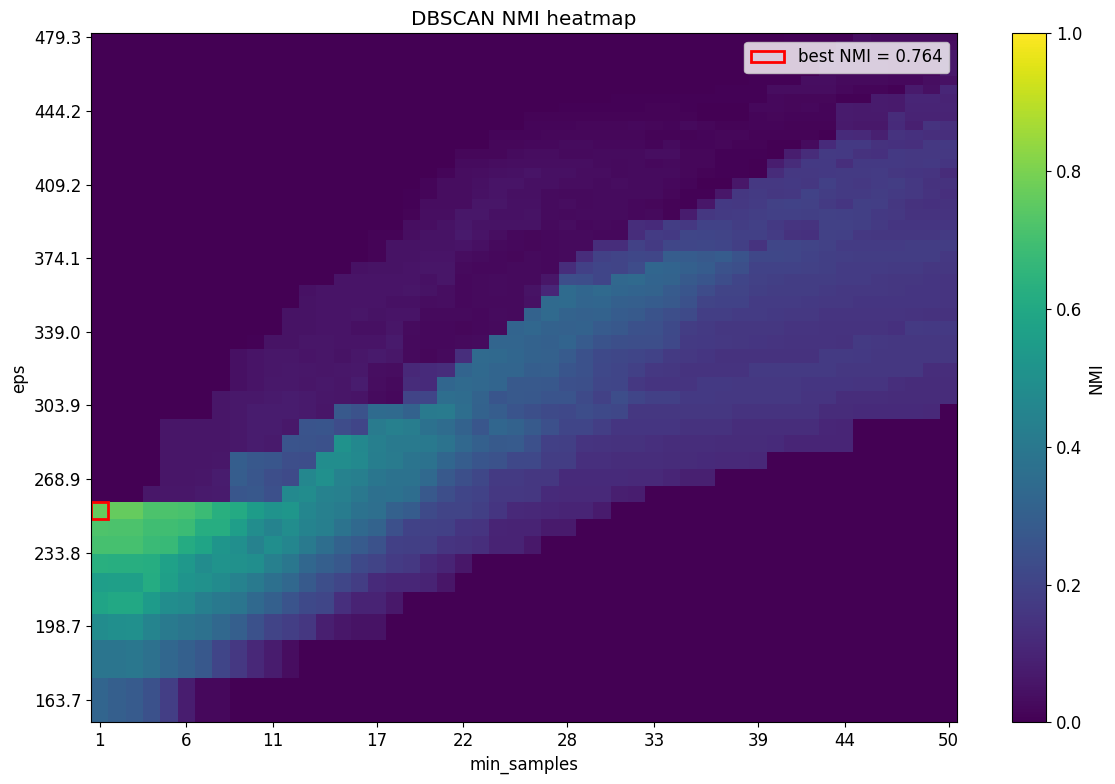

Best (min_samples, epsilon) which maximize NMI: (1, 253.96)


In [7]:
best_mP, best_eps = heatmap(nmi_grid, min_sample_range, eps_range)
print(f'Best (min_samples, epsilon) which maximize NMI: ({int(best_mP)}, {best_eps:.2f})')

The high NMI region in the heatmap indicates a trade-off between ε (epsilon) and mP (min_samples). Higher NMI values are primarily achieved with smaller mP values (e.g., mP=1) at moderate ε values (around 250-260), where DBSCAN can effectively identify dense clusters without over-merging noise. As mP increases, maintaining high NMI requires progressively larger ε to compensate for the stricter density requirements, reflecting DBSCAN's sensitivity. 

This suggests an inverse relationship in optimal parameter tuning for this dataset, with the peak NMI at ε ≈ 254 and mP=1.

- The plots of ranked distances to the i-th neighbor might help choose the ε for a given $i = mP$. How does the optimal value for ε given mP relate to the ranked distances to the mP-th neighbor? 

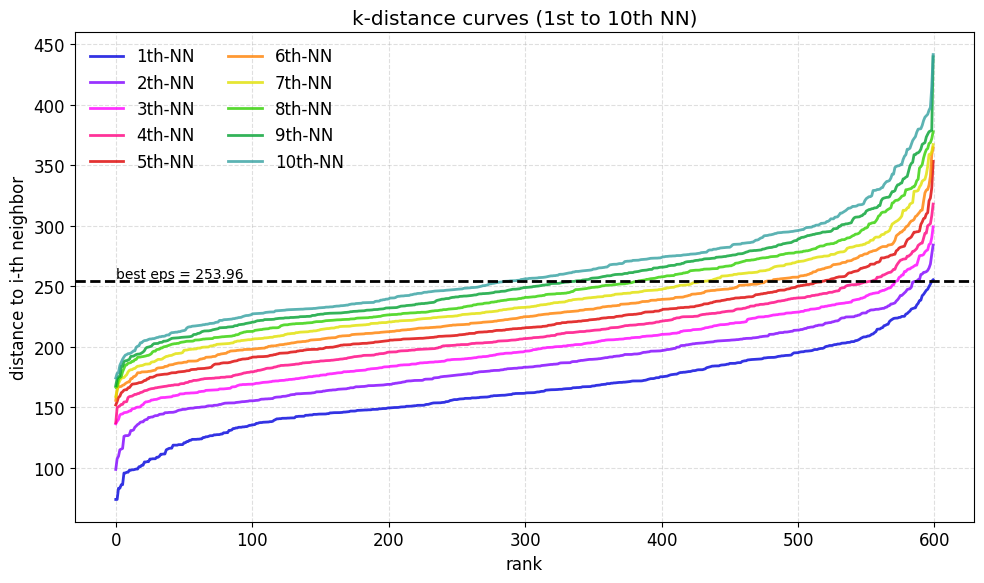

In [8]:
listc= ["#0000DD","#8000FF","#FF00FF","#FF0080","#DD0000",
        "#FF8000","#E0E000","#30D000","#00A030","#33A0A0"]

nn=10

plt.figure(figsize=(10, 6))
for i in range(1, min(11, nn+1)): 
    plt.plot(
        np.sort(dd[i]),
        c=listc[i-1],
        label=f"{i}th-NN",
        linewidth=2,
        alpha=0.8
    )
plt.xlabel("rank")

plt.axhline(best_eps, linestyle='--', color='k', linewidth=2)
plt.text(0.5, best_eps, f'best eps = {best_eps:.2f}', fontsize=10, va='bottom')

plt.ylabel("distance to i-th neighbor")
plt.title("k-distance curves (1st to 10th NN)")
plt.grid(True, linestyle="--", alpha=0.4)
plt.legend(ncol=2, frameon=False)
plt.tight_layout()
plt.show()

Looking at the ranked distance plot, we can justify why $ \text{min\_samples} = 1 $ is the most appropriate choice. Each curve represents the sorted distances from every point to its *i-th nearest neighbor*, and in particular, the 1st nearest neighbor (1-NN) curve shows the distance to the closest neighbor for all points. The selected threshold $ \varepsilon \approx 254 $, indicated by the dashed line, intersects the 1-NN curve at a relatively high rank. This indicates that most points have at least one neighbor within this distance, since the majority of the 1-NN distances lie below the chosen $ \varepsilon $.

With $ \text{min\_samples} = 1 $, DBSCAN classifies a point as a core point if it has at least one neighbor within $ \varepsilon $, which is consistent with what said before.   
Increasing $ \text{min\_samples} $ would impose a stricter density requirement, meaning that each point would need more neighbors within the same radius. As a result, a larger $ \varepsilon $ would be required to maintain connectivity between clusters. This trade-off is also reflected in the heatmap, where higher values of $ \text{min\_samples} $ correspond to larger optimal values of $ \varepsilon $.

## 2. Understanding the 12-dimensional data 

Use the principal component analysis (PCA) to visualize the first components of the data.    

Does it help understand its structure?

The fraction of the total variance encoded in the first three principal components is 0.963


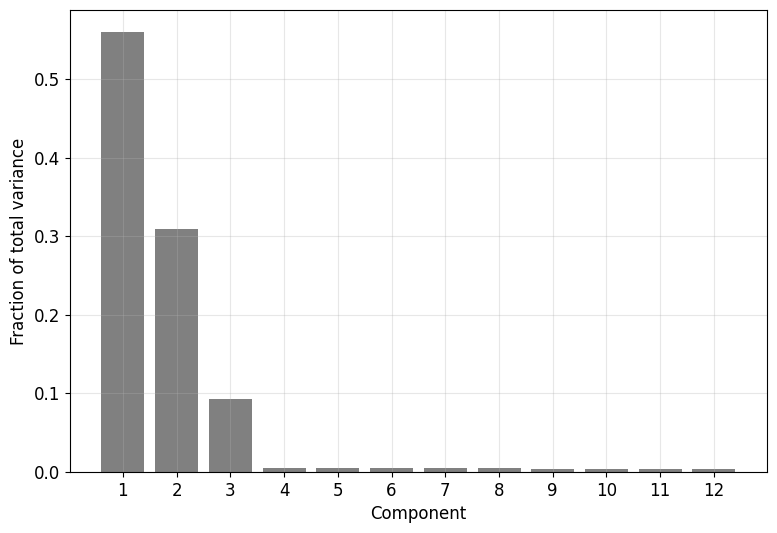

In [24]:
from sklearn.decomposition import PCA
pca = PCA(n_components=3)
X_pca = pca.fit_transform(data)

p = pca.explained_variance_ratio_.sum()

print(f'The fraction of the total variance encoded in the first three principal components is {p:.3f}')

pca_all = PCA(n_components=12)
X_pca_all = pca_all.fit(data)

plt.figure(figsize=(9,6))
plt.bar(range(1, 13), pca_all.explained_variance_ratio_, color='gray')
plt.xticks(range(1, 13))
plt.xlabel("Component")
plt.ylabel("Fraction of total variance")
plt.grid(alpha=0.3)
plt.show()

In [ ]:
from matplotlib.colors import ListedColormap
from matplotlib.ticker import MaxNLocator

plt.rcParams['font.size'] = 13
mycmap = ListedColormap(["blue","red","gold" ])

def plotting_3d(x, y):
    fig = plt.figure(figsize=(15, 5)) 
    
    for i in range(2):
        ax = fig.add_subplot(1, 2, i+1, projection='3d')
        ax.scatter(x[:,0], x[:,1], x[:,2], s=5, c=y, depthshade=True, cmap=mycmap)
        ax.view_init(25+15*i, 45*(i-1))
        
        ax.tick_params(axis='x', pad=5)
        ax.tick_params(axis='y', pad=5)
        ax.tick_params(axis='z', pad=5)
        
        ax.xaxis.set_major_locator(MaxNLocator(5))
        ax.yaxis.set_major_locator(MaxNLocator(5))
        ax.zaxis.set_major_locator(MaxNLocator(5))
        
    plt.tight_layout(w_pad=4.0) 
    
    plt.draw()
    return fig

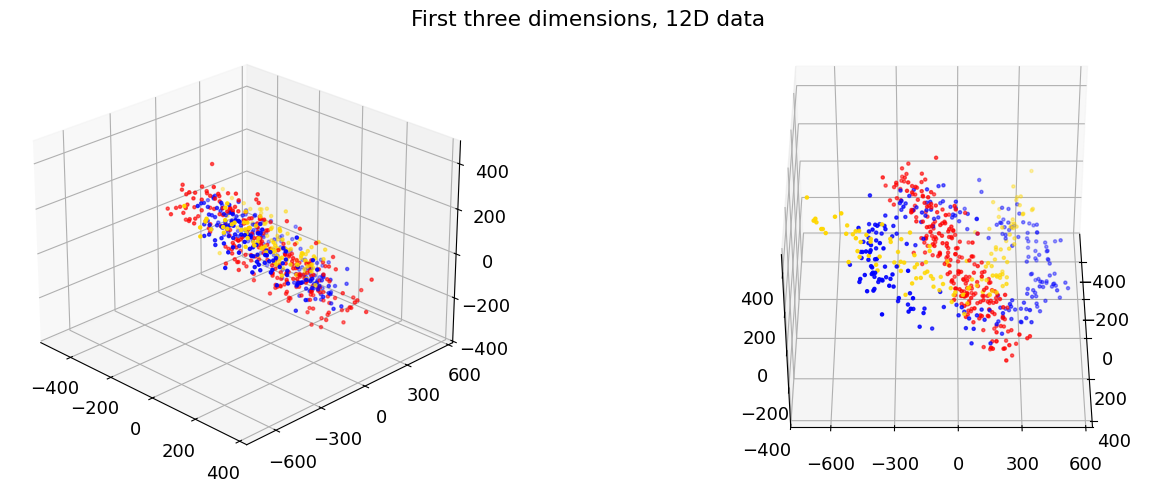

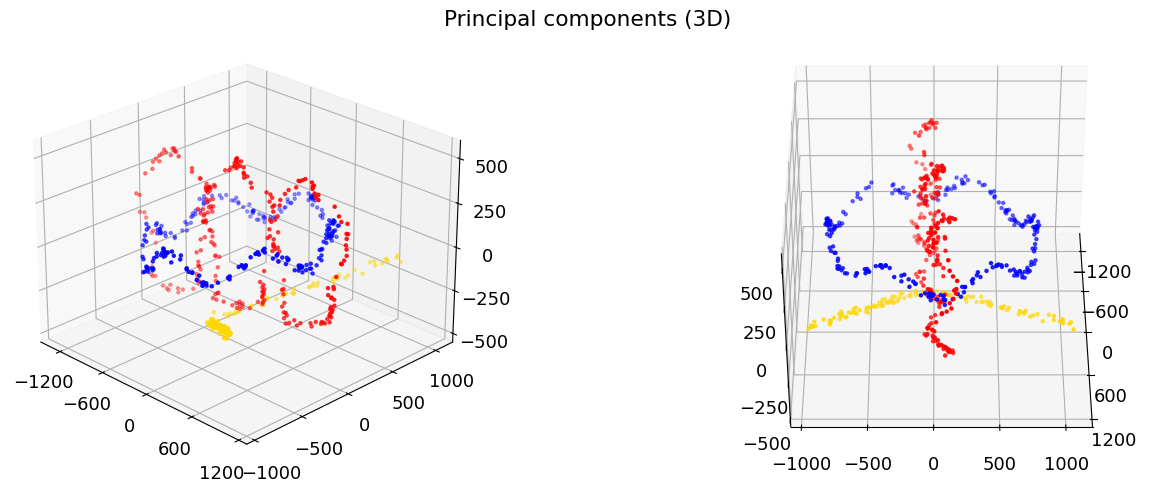

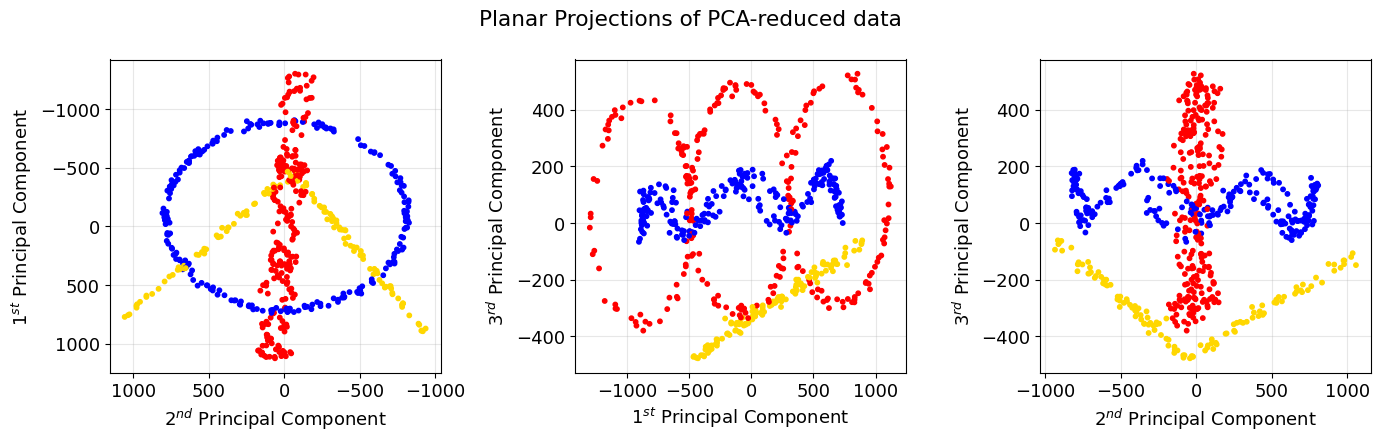

In [ ]:
# plot of the original, non-rotated data
fig2 = plotting_3d(data, y)
fig2.suptitle('First three dimensions, 12D data')

# plot of the principal components 
fig1 = plotting_3d(X_pca, y)
fig1.suptitle('Principal components (3D)')

# 2D projections
fig2, ax = plt.subplots(1, 3, figsize = (14, 4.5), layout = 'tight')
fig2.suptitle('Planar Projections of PCA-reduced data')

ax[0].scatter(X_pca[:, 1], X_pca[:, 0], s=10, c=y, cmap=mycmap, zorder = 3)
ax[1].scatter(X_pca[:, 0], X_pca[:, 2], s=10, c=y, cmap=mycmap, zorder = 3)
ax[2].scatter(X_pca[:, 1], X_pca[:, 2], s=10, c=y, cmap=mycmap, zorder = 3)

ax[0].grid(alpha=0.3)
ax[1].grid(alpha=0.3)
ax[2].grid(alpha=0.3)

ax[0].set_ylabel(r'$1^{st}$ Principal Component')
ax[0].set_xlabel(r'$2^{nd}$ Principal Component')
ax[0].invert_yaxis()
ax[0].invert_xaxis()

ax[1].set_xlabel(r'$1^{st}$ Principal Component')
ax[1].set_ylabel(r'$3^{rd}$ Principal Component')

ax[2].set_xlabel(r'$2^{nd}$ Principal Component')
ax[2].set_ylabel(r'$3^{rd}$ Principal Component')
plt.show()


By performing PCA it is possible to visualize in a much better way the info contained in the dataset, such as possible patterns, as shown by the above graphs.

We then reproduced the heatmap by applying DBSCAN to the compressed dataset (n = 3).
In order to do this properly, since the PCA procedure modifies the distances between points, we need to recompute the range of interest for $\epsilon$, feeding the rotated and compressed data to the algorithm.


In [ ]:
nn = 50 # nearest n
nbrs = NearestNeighbors(n_neighbors=nn+1).fit(X_pca) #, algorithm='ball_tree'

# distances
d_pca, ind = nbrs.kneighbors(X_pca)
dd_pca=d_pca.T

# eps and minsample range 
eps_range_pca = np.mean(dd_pca,axis=1)[1:]
print(f"Epsilon range for PCA data:= \n {eps_range_pca}")
min_sample_range_pca = np.array([i for i in range(1,nn+1)])
print(f"mP range for:= \n {min_sample_range}")

Epsilon range for PCA data:= 
 [ 29.2540581   42.43745163  53.85798138  65.73601019  76.73858629
  90.23754918 104.42269551 118.68954009 131.78266883 144.23996733
 157.39412799 169.76335928 181.55047578 194.01021371 204.58585933
 214.47614523 225.34355296 235.03078677 244.67987408 254.04358601
 263.42671478 271.1743315  279.2767507  285.99872097 293.05587123
 299.86123594 306.86881454 313.02823219 319.18982302 324.68326595
 330.71039387 336.98305633 342.30189584 348.07649266 353.67491681
 359.07238322 364.68787527 369.81135245 375.04111624 380.02987637
 385.00216776 390.14143583 394.36195013 399.1243165  403.89737715
 408.74042399 413.73132709 418.76051652 423.09120041 427.81805359]
mP range for:= 
 [ 1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20 21 22 23 24
 25 26 27 28 29 30 31 32 33 34 35 36 37 38 39 40 41 42 43 44 45 46 47 48
 49 50]


In [ ]:
mP_grid_pca, eps_grid_pca = np.meshgrid(min_sample_range_pca, eps_range_pca)
nmi_grid_pca = np.zeros_like(mP_grid_pca, dtype=float)

for i in range(mP_grid_pca.shape[0]):
    for j in range(mP_grid_pca.shape[1]):
        model = DBSCAN(eps=eps_grid_pca[i, j], min_samples=mP_grid_pca[i, j])
        model.fit(X_pca)
        y_pred = model.labels_
        nmi_grid_pca[i, j] = NMI(y_true, y_pred)

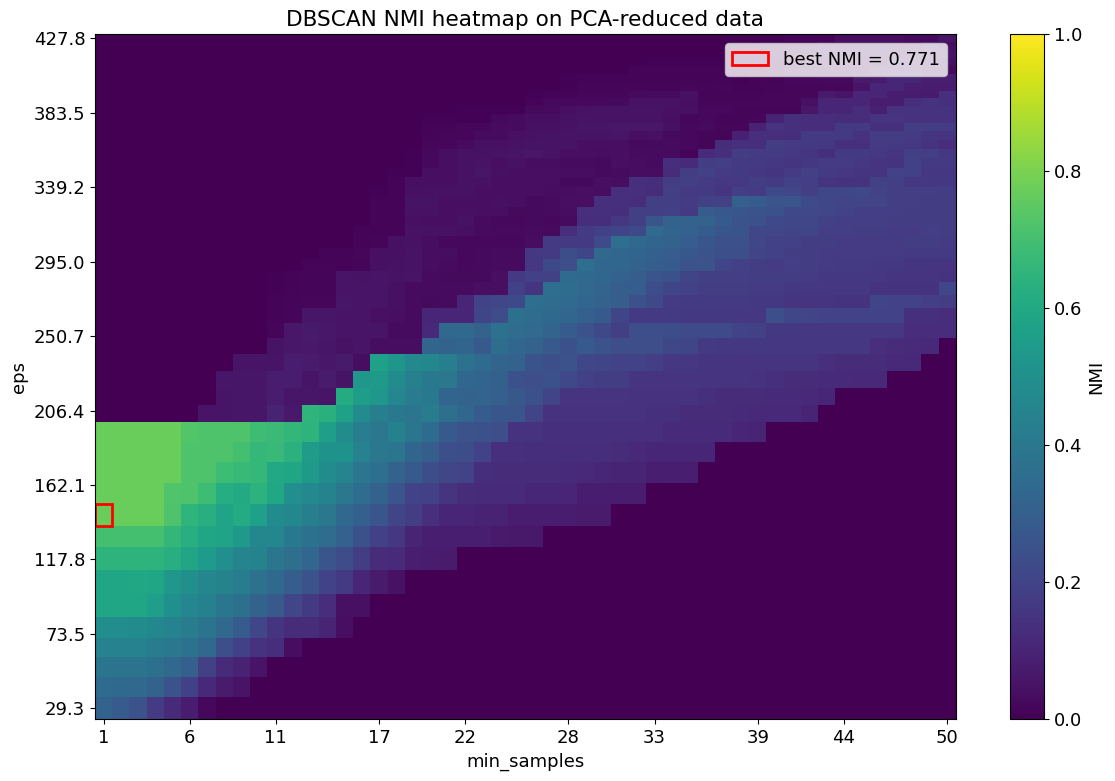

Best (min_samples, epsilon) which maximize NMI: (1, 144.24)


In [ ]:
best_mP_2, best_eps_2 = heatmap(nmi_grid_pca, min_sample_range_pca, eps_range_pca, title='DBSCAN NMI heatmap on PCA-reduced data')
print(f'Best (min_samples, epsilon) which maximize NMI: ({int(best_mP_2)}, {best_eps_2:.2f})')

The behaviour shown in this graph is the same as the one for the DBSCAN performed on the full dataset, with a higher value for NMI corresponding to a lower $\epsilon$ and a lower number of `min_samples`. Also the maximum NMI value slightly increases, highlighting the fact that the remaining 4% of variance exluded by the PCA procedure contained only noise, and not valuable information about our dataset. Not considering these fluctuations allowed the algorithm to be more precise in the calculations of the distances between points, thus yielding a better score.

Another major difference between the two cases lies in the respective values for $\epsilon$. To highlight this, we plot once again the ranked distances graph.

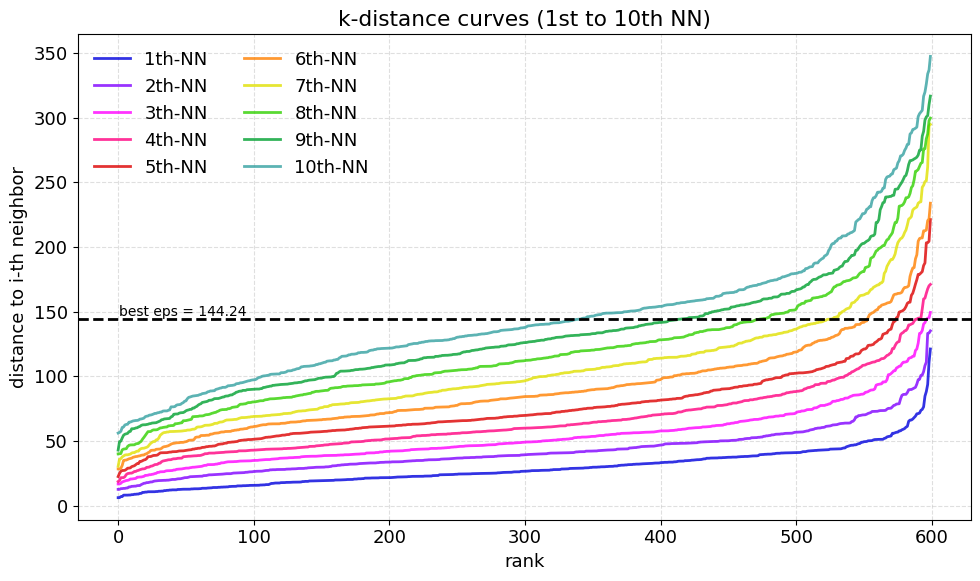

In [ ]:
listc= ["#0000DD","#8000FF","#FF00FF","#FF0080","#DD0000",
        "#FF8000","#E0E000","#30D000","#00A030","#33A0A0"]

nn=10

plt.figure(figsize=(10, 6))
for i in range(1, min(11, nn+1)): 
    plt.plot(
        np.sort(dd_pca[i]),
        c=listc[i-1],
        label=f"{i}th-NN",
        linewidth=2,
        alpha=0.8
    )
plt.xlabel("rank")

plt.axhline(best_eps_2, linestyle='--', color='k', linewidth=2)
plt.text(0.5, best_eps_2, f'best eps = {best_eps_2:.2f}', fontsize=10, va='bottom')

plt.ylabel("distance to i-th neighbor")
plt.title("k-distance curves (1st to 10th NN)")
plt.grid(True, linestyle="--", alpha=0.4)
plt.legend(ncol=2, frameon=False)
plt.tight_layout()
plt.show()

The compression of data points after the PCA procedure is now evident in the different behaviour of the slopes at low-rank neighbours, and also in the fact that distances are generally smaller.

## 3. Compare with K-MEANS algorithm

Perform a k-means clustering of the data, with k=3. Does it work better than DBSCAN? Why? 

Firstly, we perform a k-means clustering on the original 12D dataset, evaluating the NMI score and visualizing the results:

In [ ]:
from sklearn.cluster import KMeans

model = KMeans(n_clusters=3, 
               n_init=100, init='k-means++',
                random_state=42)

y_pred = model.fit_predict(data)
nmi_kmeans = NMI(y, y_pred)
print(f"NMI per K-Means (k=3): {nmi_kmeans:.3f}")


NMI per K-Means (k=3): 0.126


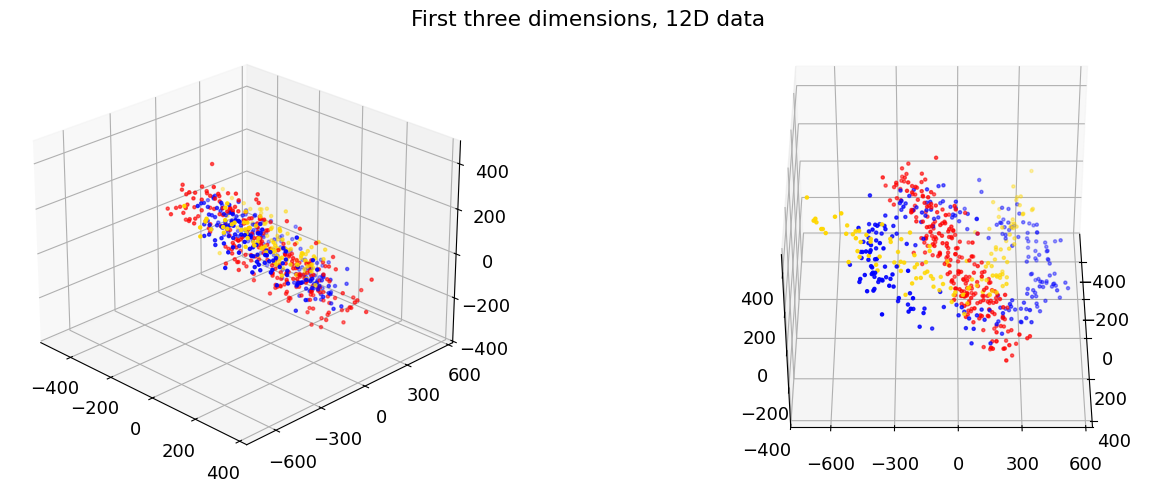

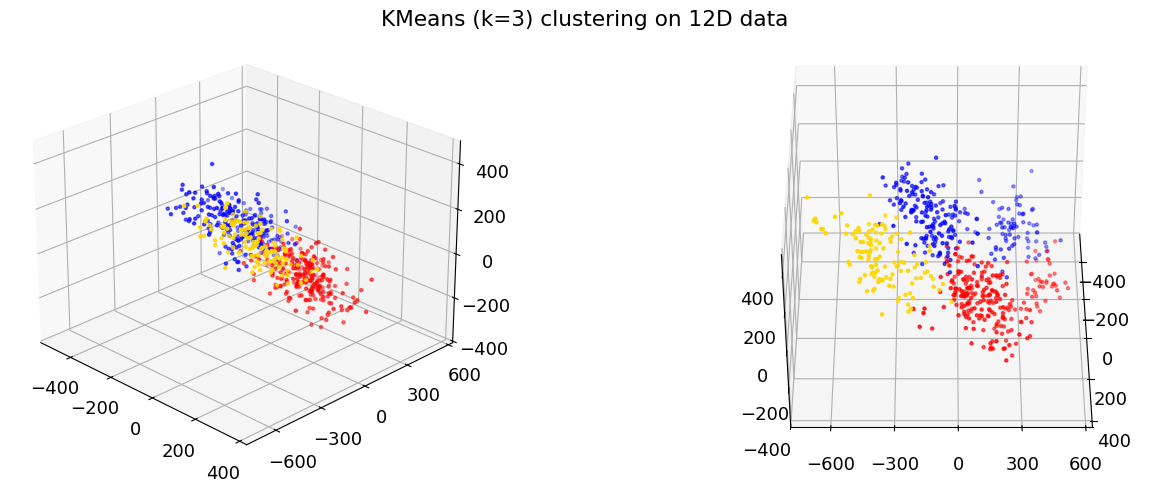

In [ ]:
# plot of the original, non-rotated data
fig3 = plotting_3d(data, y)
fig3.suptitle('First three dimensions, 12D data')

# KMeans clustering
fig4 = plotting_3d(data, y_pred)
fig4.suptitle('KMeans (k=3) clustering on 12D data ')
plt.show()

The results is clearly worse than the one obtained through DBSCAN.
Let us also evaluate the performance on clustering on the PCA-reduced dataset. 

In [ ]:
y_pred_2 = model.fit_predict(X_pca)
nmi_kmeans_2 = NMI(y, y_pred_2)
print(f"NMI per K-Means (k=3): {nmi_kmeans_2:.3f}")

NMI per K-Means (k=3): 0.126


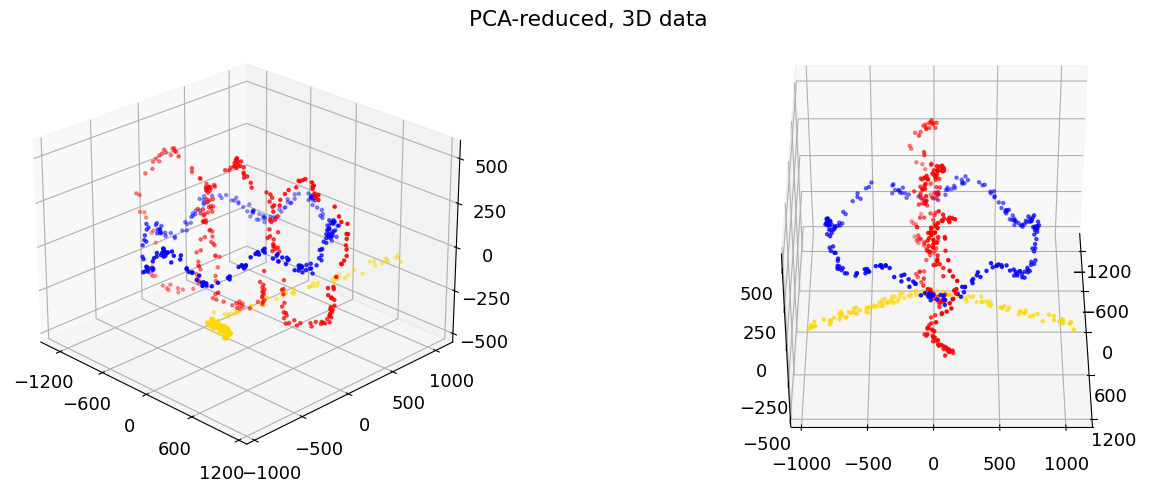

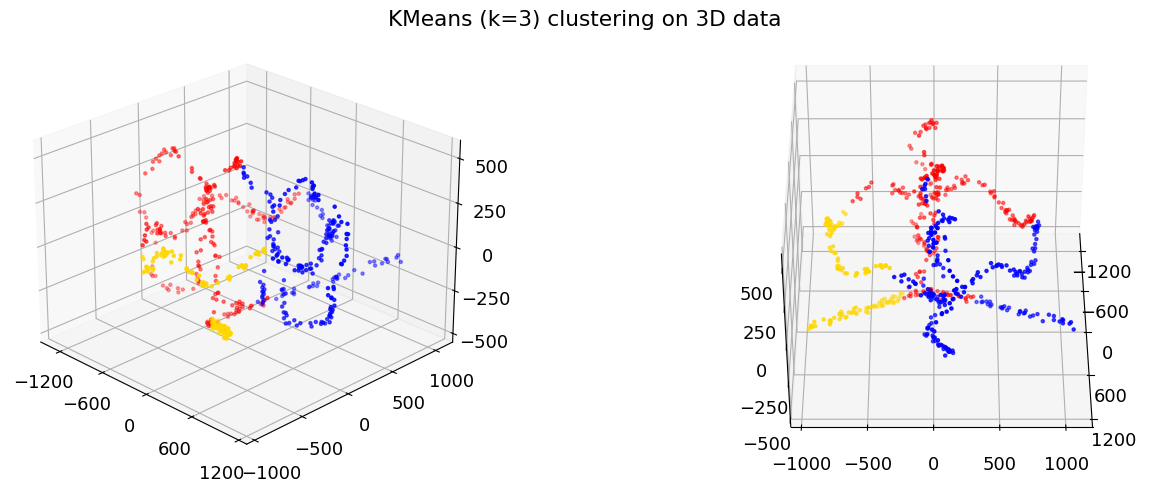

In [ ]:
# plot of the original PCA reduced data
fig4 = plotting_3d(X_pca, y)
fig4.suptitle('PCA-reduced, 3D data')

# KMeans clustering 
fig5 = plotting_3d(X_pca, y_pred)
fig5.suptitle('KMeans (k=3) clustering on 3D data ')
plt.show()

The quality of the result is the same: KMeans is not able to perform well on this dataset.

We can conclude that this is because KMeans assumes all clusters to have a spherical shape (in n dimensions), and therefore it is not able to distinguish them properly, when their shape is of more complex type. DBSCAN, on the other hand, computes the labels based on the distance between points, thus forming groups only based on the density of points, whatever shape they assume. In this case, given our specific dataset, DBSCAN thus works best, and the PCA procedure actually made us reach a better result, 'cleaning' away random noise and comopressing distances between points with the same label. 

In the following conclusive table we present the NMI scores for the various cases:

| **NMI Scores** | **12D data** | **PCA-reduced data (3D)** |
| -------------- | -------------| ------------------------  |
| DBSCAN         | 0.764        | 0.771                     |
| KMeans (k=3)   | 0.126        | 0.126                     |
